# Supplementary figure: robustness to sequencing depth and training-cohort size

Composite of panels from `figS8.ipynb` and `figS9.ipynb` (code copied from them). Top row (a-d):
BRCA/CRC versus healthy; bottom row (e-h): pan-cancer versus healthy.
- a, e: mean ROC over the ten outer test folds, by sequencing depth;
- b, f: classification metrics at the 95%-specificity threshold, by depth;
- c, g: AUROC of every outer fold by depth, with paired tests;
- d, h: AUROC against training-cohort size.

Depth arms: *full depth* (the fully nested model on the samples as sequenced); *full-depth model
applied to 1x / 0.1x* (the same fold models tested on downsampled test samples); *retrained at
1x / 0.1x* (the nested procedure repeated on downsampled samples). Outer folds are shared, so folds
are paired.

Source data (`data/no_deep/`): `figS8_predictions.csv`, `figS8_config.csv`, `figS8_fold_configs.csv`
(from `export/export_figS8.py`); `figS9_predictions.csv`, `figS9_sweep.csv`,
`figS9_seed_replicates.csv` (from `export/export_figS9.py`).

Output: `output/no_deep/figS_depth_size.png` (600 dpi, 180 mm wide) and `.pdf`. The checks cell
compares the plotted numbers with the expected values.

In [1]:
import os
import time

# Data paths are relative to src/figures/; change there if the kernel started elsewhere.
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))

# Cohort: "no_deep" (default; data/no_deep/, output/no_deep/) or "all" (data/, output/), via FIG_COHORT.
COHORT = os.environ.get("FIG_COHORT", "no_deep")
assert COHORT in ("all", "no_deep"), COHORT
_DATA = "data" if COHORT == "all" else os.path.join("data", COHORT)
_OUT = "output" if COHORT == "all" else os.path.join("output", COHORT)
os.makedirs(_OUT, exist_ok=True)
_FALLBACKS = set()


def data_path(name):
    """Source-data path for the selected cohort (full-cohort fallback with a notice)."""
    p = os.path.join(_DATA, name)
    if COHORT != "all" and not os.path.exists(p):
        if name not in _FALLBACKS:
            print(f"   [cohort {COHORT}] {name} not exported for this cohort - using the full-cohort file")
            _FALLBACKS.add(name)
        p = os.path.join("data", name)
    return p


def out_path(name):
    """Output path for the selected cohort."""
    return os.path.join(_OUT, name)


def savefig(fig, name, **kw):
    """fig.savefig with retries (the figures folder can be on a network drive)."""
    for attempt in range(4):
        try:
            fig.savefig(out_path(name), **kw)
            return
        except OSError:
            if attempt == 3:
                raise
            time.sleep(2 * (attempt + 1))


print(f"cohort: {COHORT} (source data from {_DATA}/, figures to {_OUT}/)")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import _figstyle as fs
fs.apply()
import itertools
from scipy import stats
from scipy.interpolate import interp1d
from sklearn.metrics import roc_curve, auc

TASK_LABELS = {"brca_crc": "BRCA/CRC versus healthy", "pancan": "Pan-cancer versus healthy"}

# --- depth arms (Fig S8) ----------------------------------------------------------
# "full", "cov1x", "cov0.1x": the nested procedure run at that depth. "xd_*": the
# full-depth fold models re-evaluated on the downsampled test folds.
DEPTH_ORDER_ALL = ["full", "xd_cov1x", "cov1x", "xd_cov0.1x", "cov0.1x"]
CORE_DEPTHS = ["full", "cov1x", "cov0.1x"]
# Full-depth models on downsampled test samples: solid, dark; retrained models: dashed, pale.
DEPTH_LABELS = {"full": "Full depth",
                "xd_cov1x": "Full-depth model applied to 1x",
                "cov1x": "Retrained at 1x",
                "xd_cov0.1x": "Full-depth model applied to 0.1x",
                "cov0.1x": "Retrained at 0.1x"}
DEPTH_COLORS = {"full": fs.METHOD["Data-driven"],   # the data-driven blue of the shared figure style
                "xd_cov1x": "#029E73",   # green
                "cov1x": "#7CCBA2",      # pale green
                "xd_cov0.1x": "#D55E00", # vermilion
                "cov0.1x": "#F4A261"}    # pale orange
DEPTH_DASHED = {"cov1x", "cov0.1x"}
# tick labels of the per-fold panel: depth of the test samples ("retrained" = retrained at that depth)
SHORT_LABELS = {"full": "Full\ndepth",
                "xd_cov1x": "1x", "cov1x": "1x\nretrained",
                "xd_cov0.1x": "0.1x", "cov0.1x": "0.1x\nretrained"}

# --- text sizes of the composite (four panels per row) --------------------------------
# shared figure style (_figstyle), drawn at the printed size
FS_AXIS, FS_TICK, FS_LEGEND, FS_VALUE = fs.FONT, fs.SMALL, fs.SMALL, fs.VALUE
TITLE_PAD = 16   # pt; aligns the titles with the cohort-size panel, which has a top axis


def task_depths(pred, task):
    present = set(pred[pred["task"] == task]["depth"])
    return [d for d in DEPTH_ORDER_ALL if d in present]


def box_spines(ax):
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.0)
        spine.set_color("black")

cohort: no_deep (source data from data\no_deep/, figures to output\no_deep/)


## Source data

In [2]:
# --- sequencing depth (Fig S8 data) ---------------------------------------------------
depth_pred = pd.read_csv(data_path("figS8_predictions.csv"))
depth_config = pd.read_csv(data_path("figS8_config.csv"))
depth_fold_cfg = pd.read_csv(data_path("figS8_fold_configs.csv"))

TASKS = [t for t in TASK_LABELS if t in set(depth_pred["task"])]
for task in TASKS:
    sub = depth_pred[(depth_pred["task"] == task) & (depth_pred["depth"] == "full")]
    print(f"{TASK_LABELS[task]}: {sub['sample_id'].nunique()} samples "
          f"({(sub['y_true'] == 0).sum()} healthy, {(sub['y_true'] == 1).sum()} cancer), "
          f"folds: {sub['fold'].nunique()}")
    depths = task_depths(depth_pred, task)
    assert set(CORE_DEPTHS) <= set(depths), f"{task}: core depths missing from {depths}"
    print(f"  depth arms present: {depths}")

# --- training-cohort size (Fig S9 data) -----------------------------------------------
size_pred = pd.read_csv(data_path("figS9_predictions.csv"))
size_sweep = pd.read_csv(data_path("figS9_sweep.csv")).sort_values(
    ["task", "sample_fraction"], ascending=[True, False])
# Smallest subset shown: 20% (the 10% BRCA/CRC subset allows only 8 outer folds).
MIN_FRACTION = 0.2
size_pred = size_pred[size_pred["sample_fraction"] >= MIN_FRACTION - 1e-9]
size_sweep = size_sweep[size_sweep["sample_fraction"] >= MIN_FRACTION - 1e-9]
assert (size_sweep["n_outer_folds"] == 10).all(), size_sweep[["task", "sample_fraction", "n_outer_folds"]]
assert set(TASKS) == {t for t in TASK_LABELS if t in set(size_sweep["task"])}

CANONICAL_FRACTIONS = [1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2]
for task in TASKS:
    have = sorted(size_sweep.loc[size_sweep["task"] == task, "sample_fraction"], reverse=True)
    missing = [f for f in CANONICAL_FRACTIONS if not np.isclose(have, f).any()]
    assert not missing, f"{task}: cohort-size sweep incomplete, missing {missing}"
    print(f"{TASK_LABELS[task]}: cohort-size sweep complete ({len(have)} fractions)")

# Replicate subsample seeds at the small fractions (across-seed band; none -> no band).
REP_COLS = ["task", "subsample_seed", "sample_fraction", "n_samples",
            "n_outer_folds", "mean_test_auc", "std_test_auc",
            "oof_auc_pooled", "source_dir"]
try:
    SIZE_REPS = pd.read_csv(data_path("figS9_seed_replicates.csv"))
except FileNotFoundError:
    SIZE_REPS = pd.DataFrame(columns=REP_COLS)
SIZE_REPS = SIZE_REPS[SIZE_REPS["sample_fraction"] >= MIN_FRACTION - 1e-9]
for task in TASKS:
    r = SIZE_REPS[SIZE_REPS["task"] == task]
    if len(r):
        print(f"  {task}: replicate subsample seeds "
              f"{sorted(int(s) for s in r['subsample_seed'].unique())} at fractions "
              f"{', '.join(f'{f:.0%}' for f in sorted(r['sample_fraction'].unique(), reverse=True))}")
    else:
        print(f"  {task}: no subsample-seed replicates - across-seed band omitted")

print()
print(size_sweep[["task", "sample_fraction", "n_samples", "n_outer_folds",
                  "mean_test_auc", "std_test_auc", "modal_feature", "modal_classifier"]]
      .to_string(index=False, float_format=lambda v: f"{v:.3f}"))

BRCA/CRC versus healthy: 244 samples (164 healthy, 80 cancer), folds: 10
  depth arms present: ['full', 'xd_cov1x', 'cov1x', 'xd_cov0.1x', 'cov0.1x']
Pan-cancer versus healthy: 367 samples (164 healthy, 203 cancer), folds: 10
  depth arms present: ['full', 'xd_cov1x', 'cov1x', 'xd_cov0.1x', 'cov0.1x']
BRCA/CRC versus healthy: cohort-size sweep complete (9 fractions)
Pan-cancer versus healthy: cohort-size sweep complete (9 fractions)
  brca_crc: replicate subsample seeds [43, 44, 45] at fractions 40%, 30%, 20%
  pancan: replicate subsample seeds [43, 44, 45] at fractions 40%, 30%, 20%

    task  sample_fraction  n_samples  n_outer_folds  mean_test_auc  std_test_auc modal_feature       modal_classifier
brca_crc            1.000        244             10          0.966         0.029  griffin_diff Support Vector Machine
brca_crc            0.900        220             10          0.961         0.053  griffin_diff Support Vector Machine
brca_crc            0.800        195             10   

## Helpers

In [3]:
def fold_rocs(df):
    """Per-fold ROC curves and AUROCs from out-of-fold scores."""
    out = []
    for _, g in df.groupby("fold"):
        fpr, tpr, _ = roc_curve(g["y_true"], g["score"])
        out.append((fpr, tpr, auc(fpr, tpr)))
    return out


def binary_metrics(y, y_hat):
    tn = int(np.sum((y == 0) & (y_hat == 0)))
    fp = int(np.sum((y == 0) & (y_hat == 1)))
    fn = int(np.sum((y == 1) & (y_hat == 0)))
    tp = int(np.sum((y == 1) & (y_hat == 1)))
    m = {
        "recall": tp / (tp + fn) if tp + fn else 0.0,
        "accuracy": (tp + tn) / (tp + tn + fp + fn),
        "specificity": tn / (tn + fp) if tn + fp else 0.0,
    }
    # Precision/F1 are undefined when a fold makes no positive predictions
    # (TP+FP == 0); those folds are skipped for precision/F1 only.
    if tp + fp:
        m["precision"] = tp / (tp + fp)
        m["f1-score"] = 2 * m["precision"] * m["recall"] / (m["precision"] + m["recall"]) \
            if (m["precision"] + m["recall"]) else 0.0
    return m


def collect_fold_metrics(task, depth):
    """Per-fold metrics at the fold's train-derived 95%-specificity threshold."""
    df = depth_pred[(depth_pred["task"] == task) & (depth_pred["depth"] == depth)]
    out = {k: [] for k in ["precision", "recall", "f1-score", "accuracy", "specificity"]}
    for _, g in df.groupby("fold"):
        thr = g["threshold_95spec"].iloc[0]
        m = binary_metrics(g["y_true"].to_numpy(), (g["score"] >= thr).astype(int).to_numpy())
        for k, v in m.items():
            out[k].append(v)
    return out


def size_fold_aucs(df):
    """AUROC of every outer fold, in fold order."""
    return np.array([a for _, _, a in fold_rocs(df)])

## Sequencing-depth panels (Fig S8)

In [4]:
def panel_depth_roc(ax, task):
    """Mean ROC by depth arm; the legend gives the AUROC (mean +/- SD over the outer folds) of each arm, its line
    style and color identify the arm (names in the shared legend below the figure)."""
    base_fpr = np.linspace(0, 1, 101)
    for depth in task_depths(depth_pred, task):
        color = DEPTH_COLORS[depth]
        df = depth_pred[(depth_pred["task"] == task) & (depth_pred["depth"] == depth)]
        tprs, aucs = [], []
        for fpr, tpr, a in fold_rocs(df):
            tprs.append(interp1d(fpr, tpr, kind="linear")(base_fpr))
            aucs.append(a)
        mean_tpr = np.mean(tprs, axis=0)
        mean_tpr[0], mean_tpr[-1] = 0, 1
        std_tpr = np.std(tprs, axis=0)
        dashed = depth in DEPTH_DASHED
        ax.plot(base_fpr, mean_tpr, color=color, linewidth=1.0 if dashed else 1.2,
                linestyle="--" if dashed else "-",
                label=f"{np.mean(aucs):.3f} ± {np.std(aucs):.3f}")
        if not dashed:
            ax.fill_between(base_fpr, np.maximum(mean_tpr - std_tpr, 0),
                            np.minimum(mean_tpr + std_tpr, 1), color=color, alpha=0.15, linewidth=0)
    ax.plot([0, 1], [0, 1], color=fs.CHANCE, ls=":", linewidth=0.8)
    ax.axvline(x=0.05, color="dimgray", linestyle=(0, (1, 1.5)), linewidth=0.8, zorder=1)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.set_xticks([0, 0.5, 1]); ax.set_yticks([0, 0.5, 1])
    # below the diagonal, where no curve runs
    leg = ax.legend(loc="lower right", title="AUROC ± SD", handlelength=0.8, handletextpad=0.3,
                    borderaxespad=0.05, borderpad=0.1, labelspacing=0.12)
    leg._legend_box.align = "left"


def panel_depth_metrics(ax, task, error_type="sem"):
    metric_names = ["Precision", "Sensitivity\n(recall)", "F1 score", "Accuracy", "Specificity"]
    metric_keys = ["precision", "recall", "f1-score", "accuracy", "specificity"]
    x = np.arange(len(metric_names))
    depths = task_depths(depth_pred, task)
    width = 0.95 / len(depths)   # touching bars: each value label stays within its own bar's column
    for idx, depth in enumerate(depths):
        m = collect_fold_metrics(task, depth)
        means = [np.mean(m[k]) if m[k] else 0 for k in metric_keys]
        if error_type == "sem":
            errs = [np.std(m[k], ddof=1) / np.sqrt(len(m[k])) if len(m[k]) > 1 else 0
                    for k in metric_keys]
        else:
            errs = [np.std(m[k]) if m[k] else 0 for k in metric_keys]
        yerr_lo = [min(e, mu) for mu, e in zip(means, errs)]
        yerr_hi = [min(e, 1.0 - mu) for mu, e in zip(means, errs)]
        offset = (idx - (len(depths) - 1) / 2) * width
        ax.bar(x + offset, means, width, yerr=[yerr_lo, yerr_hi], label=DEPTH_LABELS[depth],
               color=DEPTH_COLORS[depth], alpha=0.85, capsize=1.0, linewidth=0,
               error_kw={"elinewidth": 0.5, "capthick": 0.5}, zorder=2)
        # value labels: vertical, inside the base of the bar; dark on pale bars, white otherwise
        for i, v in enumerate(means):
            ax.text(i + offset, 0.025, f"{v:.2f}", ha="center", va="bottom", rotation=90, fontsize=FS_VALUE,
                    color="#222222" if depth in DEPTH_DASHED else "white", zorder=4)
    ax.set_ylabel("Score")
    ax.set_xticks(x)
    ax.set_xticklabels([n.replace("\n", " ") for n in metric_names], rotation=30, ha="right", rotation_mode="anchor")
    ax.tick_params(axis="x", length=0)
    ax.set_xlim(-0.5, len(metric_names) - 0.5)
    ax.set_ylim(0, 1.03)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    fs.value_grid(ax)


def _holm_adjust(pvals):
    p = np.asarray(pvals, dtype=float)
    order = p.argsort()
    adj = np.empty_like(p)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (len(p) - rank) * p[idx])
        adj[idx] = min(running, 1.0)
    return adj


def panel_depth_paired_auroc(ax, task):
    depths = task_depths(depth_pred, task)
    per_fold = {}
    for depth in depths:
        df = depth_pred[(depth_pred["task"] == task) & (depth_pred["depth"] == depth)]
        per_fold[depth] = {f: auc(*roc_curve(g["y_true"], g["score"])[:2])
                           for f, g in df.groupby("fold")}
    folds = sorted(per_fold["full"])
    xpos = np.arange(len(depths))
    for f in folds:
        ys = [per_fold[d][f] for d in depths]
        ax.plot(xpos, ys, color="grey", lw=0.45, alpha=0.55, zorder=1)
    rng = np.random.default_rng(7)  # jitter only; fixed for reproducible layout
    for i, depth in enumerate(depths):
        ys = [per_fold[depth][f] for f in folds]
        jitter = rng.uniform(-0.05, 0.05, len(ys))
        ax.scatter(np.full(len(ys), xpos[i]) + jitter, ys, s=8,
                   color=DEPTH_COLORS[depth], edgecolor="black", linewidth=0.25, zorder=3)
        ax.hlines(np.mean(ys), xpos[i] - 0.2, xpos[i] + 0.2,
                  color=DEPTH_COLORS[depth], lw=1.5, zorder=2)

    tests = {}
    ymax = max(max(v.values()) for v in per_fold.values())
    ymin = min(min(v.values()) for v in per_fold.values())
    # Every pair of arms: two-sided Wilcoxon signed-rank test on the paired fold AUROCs, Holm-adjusted
    # over the pairs of the panel. With 10 folds the smallest unadjusted p-value is 2 / 2^10 = 0.002.
    pairs = list(itertools.combinations(depths, 2))
    raw_p = []
    for a, b in pairs:
        diffs = np.array([per_fold[a][f] - per_fold[b][f] for f in folds])
        raw_p.append(stats.wilcoxon(diffs).pvalue if np.any(diffs != 0) else 1.0)
    adj_p = _holm_adjust(raw_p)

    # Bracket levels: narrow brackets first, each on the lowest level where it overlaps no placed bracket.
    spans = {pq: (depths.index(pq[0]), depths.index(pq[1])) for pq in pairs}
    levels, placed = {}, []
    for pq in sorted(pairs, key=lambda pq: (spans[pq][1] - spans[pq][0], spans[pq][0])):
        lo, hi = spans[pq]
        lvl = 0
        while any(l == lvl and not (hi <= plo or lo >= phi) for (plo, phi), l in placed):
            lvl += 1
        levels[pq] = lvl
        placed.append(((lo, hi), lvl))
    n_levels = max(levels.values()) + 1 if levels else 0
    step = 0.085 * (ymax - ymin + 0.1)
    base = max(ymax, 1.0) + 0.55 * step
    for (a, b), p_raw, p in zip(pairs, raw_p, adj_p):
        n_higher = int(sum(per_fold[a][f] > per_fold[b][f] for f in folds))
        tests[(a, b)] = dict(p=p_raw, p_holm=p, n_first_higher=n_higher,
                             mean_a=np.mean([per_fold[a][f] for f in folds]), mean_b=np.mean([per_fold[b][f] for f in folds]))
        x1, x2 = spans[(a, b)]
        y = base + step * levels[(a, b)]
        ax.plot([x1 + 0.04, x1 + 0.04, x2 - 0.04, x2 - 0.04],
                [y - step * 0.18, y, y, y - step * 0.18], color="black", lw=0.5)
        label = f"{p:.2f}" if p >= 0.095 else f"{p:.3f}"
        ax.text((x1 + x2) / 2, y + step * 0.02, label, ha="center", va="bottom", fontsize=FS_VALUE)

    ax.set_xticks(xpos)
    ax.set_xticklabels([SHORT_LABELS[d] for d in depths])
    ax.set_xlim(-0.45, len(depths) - 0.55)
    ax.set_xlabel("Depth of the test samples")
    ax.set_ylabel("AUROC per outer fold")
    ax.text(-0.42, base + step * (n_levels - 0.35), "Holm-adjusted\np-values", ha="left", va="bottom",
            fontsize=FS_VALUE, linespacing=1.0)
    y_lo = ymin - 0.03
    ax.set_ylim(y_lo, base + step * n_levels + 0.25 * step)
    ax.set_yticks([t for t in np.round(np.arange(0.0, 1.01, 0.1), 1) if t >= y_lo])
    fs.value_grid(ax)
    return tests

## Training-cohort size panel (Fig S9)

In [5]:
SIZE_COLOR = fs.METHOD["Data-driven"]


def panel_size_auroc(ax, task, legend=True):
    sub = size_sweep[size_sweep["task"] == task].sort_values("n_samples")
    n = sub["n_samples"].to_numpy()
    mean, sd = sub["mean_test_auc"].to_numpy(), sub["std_test_auc"].to_numpy()

    # Every outer fold as its own point.
    fold_x, fold_y = [], []
    for _, row in sub.iterrows():
        a = size_fold_aucs(size_pred[(size_pred["task"] == task)
                                     & (size_pred["sample_fraction"] == row["sample_fraction"])])
        fold_x.extend([row["n_samples"]] * len(a))
        fold_y.extend(a)
    ax.plot(fold_x, fold_y, "o", color=SIZE_COLOR, alpha=0.25, markersize=2,
            markeredgewidth=0, linestyle="none", zorder=2, clip_on=False,
            label="Individual folds")

    ax.fill_between(n, np.maximum(mean - sd, 0), np.minimum(mean + sd, 1),
                    color=SIZE_COLOR, alpha=0.18, zorder=2.5, linewidth=0,
                    label="± SD over folds")
    ax.plot(n, mean, "-o", color=SIZE_COLOR, linewidth=1.1, markersize=2.8,
            zorder=4, label="Mean over folds")

    # Envelope of the mean AUROC over the main and replicate subsample seeds (same subset sizes).
    rep = SIZE_REPS[SIZE_REPS["task"] == task]
    if len(rep):
        both = pd.concat([sub[["n_samples", "mean_test_auc"]],
                          rep[["n_samples", "mean_test_auc"]]])
        env = (both.groupby("n_samples")["mean_test_auc"]
               .agg(["min", "max", "count"]).reset_index().sort_values("n_samples"))
        env = env[env["count"] >= 2]
        n_seeds = rep["subsample_seed"].nunique() + 1
        ax.fill_between(env["n_samples"], env["min"], env["max"],
                        color="#555555", alpha=0.22, linewidth=0, zorder=1.5,
                        label=f"Range over {n_seeds} draws")
        ax.plot(rep["n_samples"], rep["mean_test_auc"], "o", mfc="none",
                mec="#555555", mew=0.6, markersize=2.8, linestyle="none",
                alpha=0.9, label="Other draws (mean)")

    ax.axhline(0.5, color=fs.CHANCE, linestyle=":", linewidth=0.8)
    # fraction of the cohort on the top axis, at the exact size of every second subset
    top = ax.secondary_xaxis("top")
    marks = sub[np.isclose((sub["sample_fraction"] * 10).round() % 2, 0)]
    top.set_xticks(marks["n_samples"].to_numpy(), labels=[f"{f:.0%}" for f in marks["sample_fraction"]])
    top.tick_params(labelsize=FS_VALUE, colors="dimgray", length=2)
    top.spines["top"].set_visible(False)
    # Full 0-1 range: single folds at the smallest sizes can reach 0.
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("Training-cohort size\n(samples)")
    ax.set_ylabel("AUROC")
    if legend:
        ax.legend(loc="lower right", borderaxespad=0.1, borderpad=0.1, handlelength=1.0, handletextpad=0.4)
    fs.value_grid(ax)

## Assemble the figure

saved output\no_deep\figS_depth_size.png/.pdf at 178 x 146 mm


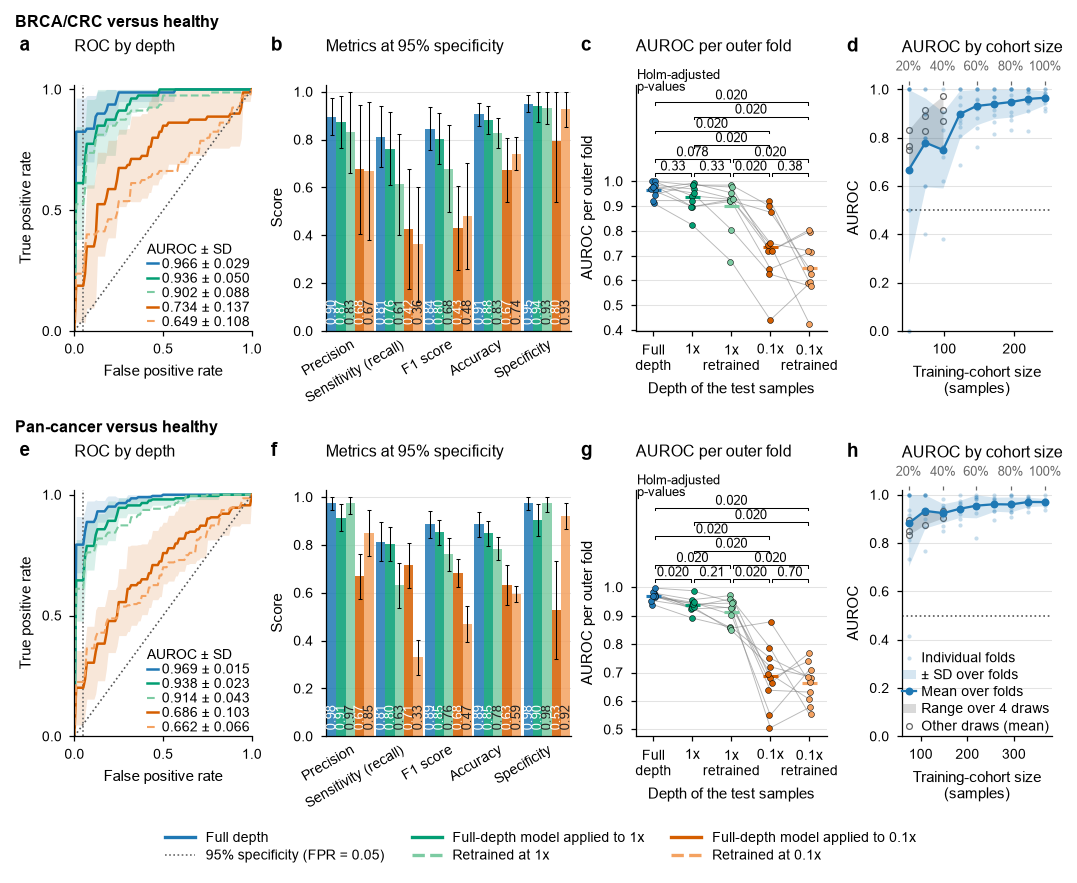

In [6]:
from matplotlib.lines import Line2D

# Shared figure style (_figstyle). The depth-arm legend (a-c, e-g) sits below the figure, the cohort-size legend in h.
PANEL_TITLES = ["ROC by depth",
                "Metrics at 95% specificity",
                "AUROC per outer fold",
                "AUROC by cohort size"]

fig = plt.figure(figsize=fs.size(height=5.75), layout="constrained")
subfigs = fig.subfigures(len(TASKS) + 1, 1, height_ratios=[1] * len(TASKS) + [0.13])
letters = iter("abcdefgh")
depth_tests = {}
for r, (sf, task) in enumerate(zip(subfigs, TASKS)):
    sf.suptitle(TASK_LABELS[task], x=0.0, ha="left", fontsize=fs.FONT + 0.5, fontweight="bold")
    axes = sf.subplots(1, 4, gridspec_kw={"width_ratios": [1.3, 1.8, 1.4, 1.1]})
    panel_depth_roc(axes[0], task)
    panel_depth_metrics(axes[1], task, error_type="std")   # standard deviation over the folds, as everywhere else
    depth_tests[task] = panel_depth_paired_auroc(axes[2], task)
    panel_size_auroc(axes[3], task, legend=(r == len(TASKS) - 1))
    for i, (ax, title) in enumerate(zip(axes, PANEL_TITLES)):
        fs.panel(ax, next(letters), title)
        if i < 3:   # level with the title of the cohort-size panel, which sits above its percentage axis
            ax.set_title(title, loc="left", pad=TITLE_PAD)

# one legend for the depth arms (line style and color as in the ROC, bar and per-fold panels)
order = ["full", "spec", "xd_cov1x", "cov1x", "xd_cov0.1x", "cov0.1x"]
handles = []
for d in order:
    if d == "spec":
        handles.append(Line2D([], [], color="dimgray", ls=(0, (1, 1.5)), lw=0.8, label="95% specificity (FPR = 0.05)"))
    elif any(d in task_depths(depth_pred, t) for t in TASKS):
        handles.append(Line2D([], [], color=DEPTH_COLORS[d], lw=1.6, ls="--" if d in DEPTH_DASHED else "-",
                              label=DEPTH_LABELS[d]))
subfigs[-1].legend(handles=handles, loc="center", ncol=3, handlelength=2.2, columnspacing=2.0)

fs.save(fig, out_path("figS_depth_size"))
plt.show()

## Checks and numbers for the caption

Mean AUROC per depth arm and cohort size, recomputed from the plotted predictions and compared with
the expected values (three decimals); the cell fails on any difference.

In [7]:
EXPECTED_DEPTH = {   # mean AUROC over the ten outer folds
    "brca_crc": {"full": 0.966, "cov1x": 0.902, "cov0.1x": 0.649, "xd_cov1x": 0.936, "xd_cov0.1x": 0.734},
    "pancan": {"full": 0.969, "cov1x": 0.914, "cov0.1x": 0.662, "xd_cov1x": 0.938, "xd_cov0.1x": 0.686},
}
EXPECTED_SIZE = {    # mean AUROC over the ten outer folds at n samples
    "brca_crc": {146: 0.932, 122: 0.898, 98: 0.750},
    "pancan": {184: 0.942, 148: 0.924, 74: 0.882},
}
mismatches = []


def check(what, value, expected):
    ok = abs(round(float(value), 3) - expected) < 5e-4
    print(f"    {what:<44} {value:.3f}   expected {expected:.3f}   {'ok' if ok else 'DIFFERS'}")
    if not ok:
        mismatches.append((what, round(float(value), 4), expected))


print("Sequencing depth: AUROC over the ten outer folds (mean ± SD), sensitivity and "
      "specificity at the 95%-specificity threshold (mean over folds)")
for task in TASKS:
    print(f"  {TASK_LABELS[task]}")
    for depth in task_depths(depth_pred, task):
        df = depth_pred[(depth_pred["task"] == task) & (depth_pred["depth"] == depth)]
        aucs = [a for _, _, a in fold_rocs(df)]
        assert len(aucs) == 10, (task, depth, len(aucs))
        m = collect_fold_metrics(task, depth)
        check(DEPTH_LABELS[depth], np.mean(aucs), EXPECTED_DEPTH[task][depth])
        print(f"        SD {np.std(aucs):.3f}   sensitivity {np.mean(m['recall']):.3f}   "
              f"specificity {np.mean(m['specificity']):.3f}")
        # the exporter's own summary must agree with the plotted predictions
        cfg_auc = depth_config[(depth_config["task"] == task) & (depth_config["depth"] == depth)]["mean_auc"].iloc[0]
        assert abs(cfg_auc - np.mean(aucs)) < 1e-6, (task, depth, cfg_auc, np.mean(aucs))
    print("    paired Wilcoxon signed-rank tests on the per-fold AUROCs (two-sided; Holm over the 10 pairs):")
    for (a, b), t in depth_tests[task].items():
        print(f"      {DEPTH_LABELS[a]:<33} {t['mean_a']:.3f} vs {DEPTH_LABELS[b]:<33} {t['mean_b']:.3f}: "
              f"higher in {t['n_first_higher']:2d}/10 folds, p = {t['p']:.4f}, Holm p = {t['p_holm']:.4f}")
    pd.DataFrame([dict(task=task, a=a, b=b, **t) for (a, b), t in depth_tests[task].items()]).to_csv(
        out_path(f"figS_depth_size_wilcoxon_{task}.csv"), index=False)

print("\nConfiguration selected most often over the ten outer folds (figS8_config.csv; "
      "votes from figS8_fold_configs.csv)")
for task in TASKS:
    for depth in CORE_DEPTHS:
        c = depth_config[(depth_config["task"] == task) & (depth_config["depth"] == depth)].iloc[0]
        fc = depth_fold_cfg[(depth_fold_cfg["task"] == task) & (depth_fold_cfg["depth"] == depth)]
        feat_votes = fc["feature"].value_counts()
        clf_votes = fc["classifier"].value_counts()
        print(f"  {TASK_LABELS[task]:<26} {DEPTH_LABELS[depth]:<18} feature {c['modal_feature']} "
              f"({feat_votes.get(c['modal_feature'], 0)}/{len(fc)} folds), classifier {c['modal_classifier']} "
              f"({clf_votes.get(c['modal_classifier'], 0)}/{len(fc)} folds)")
        print(f"      feature votes {feat_votes.to_dict()}; classifier votes {clf_votes.to_dict()}")

print("\nTraining-cohort size: AUROC over the ten outer folds")
for task in TASKS:
    sub = size_sweep[size_sweep["task"] == task].sort_values("n_samples", ascending=False)
    print(f"  {TASK_LABELS[task]}")
    for _, row in sub.iterrows():
        a = size_fold_aucs(size_pred[(size_pred["task"] == task)
                                     & (size_pred["sample_fraction"] == row["sample_fraction"])])
        assert len(a) == 10 and abs(a.mean() - row["mean_test_auc"]) < 1e-6, (task, row["n_samples"])
        n = int(row["n_samples"])
        if n in EXPECTED_SIZE[task]:
            check(f"{row['sample_fraction']:.0%} of the cohort, n = {n}", a.mean(), EXPECTED_SIZE[task][n])
        else:
            print(f"    {row['sample_fraction']:.0%} of the cohort, n = {n:<26} {a.mean():.3f}")
    assert set(EXPECTED_SIZE[task]) <= set(sub["n_samples"].astype(int)), task
    smallest = sub.iloc[-1]
    rep = SIZE_REPS[SIZE_REPS["task"] == task]
    print(f"    smallest fraction shown: {smallest['sample_fraction']:.0%} (n = {int(smallest['n_samples'])})")
    for frac, g in rep.groupby("sample_fraction"):
        main = sub[np.isclose(sub["sample_fraction"], frac)]["mean_test_auc"].iloc[0]
        v = np.append(g["mean_test_auc"].to_numpy(), main)
        print(f"    {frac:.0%} (n = {int(g['n_samples'].iloc[0])}): {g['subsample_seed'].nunique()} replicate "
              f"seeds + the main seed = {len(v)} seeds, mean AUROC range {v.min():.3f}-{v.max():.3f}")

# wording rules of the figure text
FORBIDDEN = ["PANCAN", "Native", "native", "AUC ", "AUC=", " vs ", "tumour", "deep-seq",
             "high-quality", "HQ"]
texts = [t.get_text() for t in fig.findobj(plt.Text) if t.get_text().strip()]
bad = [(w, t) for t in texts for w in FORBIDDEN if w in t]
assert not bad, bad
print(f"\nfigure text: {len(texts)} text elements checked against the wording rules - ok")

assert os.path.exists(out_path("figS_depth_size.png")) and os.path.exists(out_path("figS_depth_size.pdf"))
assert not mismatches, f"values that differ from the expected ones: {mismatches}"
print("all checks passed")

Sequencing depth: AUROC over the ten outer folds (mean ± SD), sensitivity and specificity at the 95%-specificity threshold (mean over folds)
  BRCA/CRC versus healthy
    Full depth                                   0.966   expected 0.966   ok
        SD 0.029   sensitivity 0.812   specificity 0.951
    Full-depth model applied to 1x               0.936   expected 0.936   ok
        SD 0.050   sensitivity 0.762   specificity 0.940
    Retrained at 1x                              0.902   expected 0.902   ok
        SD 0.088   sensitivity 0.613   specificity 0.933
    Full-depth model applied to 0.1x             0.734   expected 0.734   ok
        SD 0.137   sensitivity 0.425   specificity 0.796
    Retrained at 0.1x                            0.649   expected 0.649   ok
        SD 0.108   sensitivity 0.362   specificity 0.926
    paired Wilcoxon signed-rank tests on the per-fold AUROCs (two-sided; Holm over the 10 pairs):
      Full depth                        0.966 vs Full-depth model

  Pan-cancer versus healthy
    Full depth                                   0.969   expected 0.969   ok
        SD 0.015   sensitivity 0.813   specificity 0.976
    Full-depth model applied to 1x               0.938   expected 0.938   ok
        SD 0.023   sensitivity 0.804   specificity 0.904
    Retrained at 1x                              0.914   expected 0.914   ok
        SD 0.043   sensitivity 0.631   specificity 0.976
    Full-depth model applied to 0.1x             0.686   expected 0.686   ok
        SD 0.103   sensitivity 0.714   specificity 0.529
    Retrained at 0.1x                            0.662   expected 0.662   ok
        SD 0.066   sensitivity 0.330   specificity 0.921
    paired Wilcoxon signed-rank tests on the per-fold AUROCs (two-sided; Holm over the 10 pairs):
      Full depth                        0.969 vs Full-depth model applied to 1x    0.938: higher in 10/10 folds, p = 0.0020, Holm p = 0.0195
      Full depth                        0.969 vs Retrained at 1

    20% of the cohort, n = 74                    0.882   expected 0.882   ok
    smallest fraction shown: 20% (n = 74)
    20% (n = 74): 3 replicate seeds + the main seed = 4 seeds, mean AUROC range 0.834-0.895
    30% (n = 109): 3 replicate seeds + the main seed = 4 seeds, mean AUROC range 0.877-0.933
    40% (n = 148): 3 replicate seeds + the main seed = 4 seeds, mean AUROC range 0.904-0.932

figure text: 307 text elements checked against the wording rules - ok
all checks passed


## Cohort size: each subset against the full cohort, on the same participants

Each participant of a subset has an out-of-fold score from the subset run and from the full-cohort
run. The difference in pooled AUROC is bootstrapped at participant level (5,000 class-stratified
resamples); two-sided bootstrap p-values are Holm-adjusted over the fractions of a task.

Written to `output/no_deep/figS_size_tests.csv`.

In [8]:
from sklearn.metrics import roc_auc_score

N_BOOT = 5000


def _holm(pvals):
    p = np.asarray(pvals, dtype=float)
    order = p.argsort()
    adj = np.empty_like(p)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (len(p) - rank) * p[idx])
        adj[idx] = min(running, 1.0)
    return adj


size_rows = []
for task in TASKS:
    g = size_pred[size_pred["task"] == task]
    full = g[np.isclose(g["sample_fraction"], 1.0)].set_index("sample_id")
    assert full.index.is_unique
    for frac in sorted(g["sample_fraction"].unique(), reverse=True):
        if np.isclose(frac, 1.0):
            continue
        sub = g[np.isclose(g["sample_fraction"], frac)].set_index("sample_id")
        assert sub.index.is_unique and sub.index.isin(full.index).all(), (task, frac)
        y = sub["y_true"].to_numpy()
        assert (full.loc[sub.index, "y_true"].to_numpy() == y).all()
        s_sub, s_full = sub["score"].to_numpy(), full.loc[sub.index, "score"].to_numpy()
        rng = np.random.default_rng(42)
        pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
        diffs = np.empty(N_BOOT)
        for b in range(N_BOOT):
            idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
            diffs[b] = roc_auc_score(y[idx], s_sub[idx]) - roc_auc_score(y[idx], s_full[idx])
        lo, hi = np.percentile(diffs, [2.5, 97.5])
        p_boot = max(min(1.0, 2 * min((diffs >= 0).mean(), (diffs <= 0).mean())), 1 / N_BOOT)
        size_rows.append({"task": task, "fraction": frac, "n": len(y), "n_cancer": int(y.sum()),
                          "auroc_subset": roc_auc_score(y, s_sub),
                          "auroc_full_same_participants": roc_auc_score(y, s_full),
                          "difference": roc_auc_score(y, s_sub) - roc_auc_score(y, s_full),
                          "ci_low": lo, "ci_high": hi, "p_bootstrap": p_boot})
size_tests = pd.DataFrame(size_rows)
size_tests["p_holm"] = np.nan
for task, idx in size_tests.groupby("task").groups.items():
    size_tests.loc[idx, "p_holm"] = _holm(size_tests.loc[idx, "p_bootstrap"])
size_tests["differs"] = (size_tests["ci_high"] < 0) | (size_tests["ci_low"] > 0)
size_tests.to_csv(out_path("figS_size_tests.csv"), index=False, lineterminator="\n")
print(size_tests.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

print()
for task in TASKS:
    t = size_tests[size_tests["task"] == task].sort_values("fraction", ascending=False)
    first = t[t["differs"]].iloc[0]
    last_same = t[t["fraction"] > first["fraction"]].iloc[-1]
    # below the first fraction that differs, every smaller fraction differs as well
    assert t[t["fraction"] <= first["fraction"]]["differs"].all(), task
    print(f"{TASK_LABELS[task]}: not distinguishable from the full cohort down to "
          f"{last_same['fraction']:.0%} (n = {int(last_same['n'])}; difference {last_same['difference']:+.3f}, "
          f"95% CI {last_same['ci_low']:+.3f} to {last_same['ci_high']:+.3f}); lower from "
          f"{first['fraction']:.0%} (n = {int(first['n'])}; {first['difference']:+.3f}, "
          f"{first['ci_low']:+.3f} to {first['ci_high']:+.3f}; Holm p = {first['p_holm']:.3f})")

    task  fraction   n  n_cancer  auroc_subset  auroc_full_same_participants  difference  ci_low  ci_high  p_bootstrap  p_holm  differs
brca_crc    0.9000 220        72        0.9586                        0.9571      0.0015 -0.0134   0.0163       0.8404  1.0000    False
brca_crc    0.8000 195        64        0.9456                        0.9511     -0.0055 -0.0279   0.0141       0.5996  1.0000    False
brca_crc    0.7000 171        56        0.9469                        0.9545     -0.0076 -0.0328   0.0148       0.5228  1.0000    False
brca_crc    0.6000 146        48        0.9243                        0.9549     -0.0306 -0.0693   0.0064       0.1040  0.4160    False
brca_crc    0.5000 122        40        0.8479                        0.9567     -0.1088 -0.1756  -0.0521       0.0002  0.0016     True
brca_crc    0.4000  98        32        0.7708                        0.9479     -0.1771 -0.2727  -0.0938       0.0002  0.0016     True
brca_crc    0.3000  73        24        0.7270  